# Fase 3 — Parte 3: Evaluación final, análisis de errores e interpretación

**Grupo 10 — Ciencia de Datos**  
Universidad Nacional de Asunción · Facultad Politécnica · Ingeniería Informática

Esta parte ejecuta la evaluación definitiva del modelo campeón seleccionado en la Parte 2. El conjunto `test` se utiliza exclusivamente ahora, una sola vez, para medir generalización. No se ajustan hiperparámetros ni se reentrena el modelo con test.

**Objetivos**
1. Verificar la partición cronológica y el aislamiento de test.
2. Comparar Random Forest con las dos líneas base.
3. Analizar predicciones, residuos y errores por local/sección.
4. Interpretar predictores mediante importancia por permutación.
5. Exportar métricas, predicciones, gráficos y resumen reproducible.

> **Criterio de integridad:** no modificar el modelo ni seleccionar otro en función de estos resultados. Si el resultado no supera la línea base estacional, se reporta así; no se vuelve a ajustar sobre test.

In [2]:
import os
import sys
import json
import subprocess
from pathlib import Path

# Detectar la raíz del repositorio y montar Drive si se ejecuta en Colab.
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_BASE = Path('/content/drive/MyDrive/grupo10-data-science-main')
else:
    cwd = Path.cwd().resolve()
    RUTA_BASE = cwd.parent if cwd.name == 'notebooks' else cwd

if not (RUTA_BASE / 'requirements.txt').exists():
    raise FileNotFoundError(f"No encuentro requirements.txt en {RUTA_BASE}. Ajustá RUTA_BASE.")

# Instalar dependencias del proyecto, incluida la versión compatible con los modelos serializados.
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(RUTA_BASE / 'requirements.txt')])

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

SEMILLA = 42
np.random.seed(SEMILLA)

if not (RUTA_BASE / 'data' / 'panel_modelado.parquet').exists():
    raise FileNotFoundError(
        f"No encuentro data/panel_modelado.parquet dentro de {RUTA_BASE}. "
        "Ajustá RUTA_BASE a la carpeta raíz del repositorio."
    )

sys.path.insert(0, str(RUTA_BASE / 'src'))
from evaluacion_fase3 import ejecutar_evaluacion

print(f"Raíz del proyecto: {RUTA_BASE}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raíz del proyecto: /content/drive/MyDrive/grupo10-data-science-main
Python: 3.13.18 | pandas: 2.2.3 | scikit-learn: 1.9.1


## 1. Ejecución de la evaluación reservada

La función verifica las cantidades esperadas (2.835 filas de train y 594 de test), la separación temporal y la disponibilidad de las variables requeridas. La línea base de media se calcula con train; la ingenua estacional utiliza `lag_7`; Random Forest se carga desde el artefacto entrenado en la Parte 2.

In [3]:
resultados = ejecutar_evaluacion(RUTA_BASE, n_repeats=20)

print("Evaluación final completada.")
print(json.dumps(resultados['resumen'], ensure_ascii=False, indent=2))

Evaluación final completada.
{
  "modelo_campeon": "Random Forest Regressor",
  "fecha_inicio_test": "2021-08-19",
  "fecha_fin_test": "2021-09-30",
  "n_train": 2835,
  "n_test": 594,
  "metricas_test": [
    {
      "Modelo": "Base 1 — media por local × sección",
      "n": 594,
      "RMSE": 1077.2431680818127,
      "MAE": 603.789082990959,
      "MAPE_%": 67.40258376526695,
      "R2": 0.7809569615268409,
      "filas_excluidas_MAPE": 0
    },
    {
      "Modelo": "Base 2 — ingenua estacional (lag-7)",
      "n": 594,
      "RMSE": 700.6424405079651,
      "MAE": 317.97842777777777,
      "MAPE_%": 39.45459549180469,
      "R2": 0.9073394573000135,
      "filas_excluidas_MAPE": 0
    },
    {
      "Modelo": "Random Forest — modelo campeón",
      "n": 594,
      "RMSE": 547.6542647398601,
      "MAE": 239.61244287941489,
      "MAPE_%": 37.73968659777452,
      "R2": 0.9433871646519921,
      "filas_excluidas_MAPE": 0
    }
  ],
  "reduccion_rmse_vs_lag7_pct": 21.83541374644516,

## 2. Comparación de métricas en test

RMSE y MAE se expresan en unidades vendidas. MAPE se calcula excluyendo únicamente objetivos iguales a cero. R² mide la proporción de variabilidad explicada en el conjunto de prueba.

In [4]:
display(resultados['metricas'].round(4))

rf = resultados['resumen']['metricas_test'][2]
lag7 = resultados['resumen']['metricas_test'][1]
if rf['RMSE'] < lag7['RMSE']:
    print(f"Random Forest reduce el RMSE {resultados['resumen']['reduccion_rmse_vs_lag7_pct']:.2f}% frente a lag-7.")
else:
    print(f"Random Forest NO supera lag-7 en RMSE. Diferencia relativa: {resultados['resumen']['reduccion_rmse_vs_lag7_pct']:.2f}%.")
if rf['MAE'] < lag7['MAE']:
    print(f"Random Forest reduce el MAE {resultados['resumen']['reduccion_mae_vs_lag7_pct']:.2f}% frente a lag-7.")
else:
    print("Random Forest NO supera lag-7 en MAE.")

,n,RMSE,MAE,MAPE_%,R2,filas_excluidas_MAPE
Modelo,,,,,,
Base 1 — media por local × sección,594,1077.2432,603.7891,67.4026,0.7810,0
Base 2 — ingenua estacional (lag-7),594,700.6424,317.9784,39.4546,0.9073,0
Random Forest — modelo campeón,594,547.6543,239.6124,37.7397,0.9434,0


Random Forest reduce el RMSE 21.84% frente a lag-7.
Random Forest reduce el MAE 24.65% frente a lag-7.


## 3. Valores reales frente a predichos y análisis de residuos

En el gráfico real vs. predicho, los puntos cercanos a la diagonal representan predicciones más precisas. En residuos, se espera una nube sin patrón claro alrededor de cero. Curvaturas, abanicos o agrupamientos pueden señalar sesgo, heterocedasticidad o segmentos con comportamiento diferente.

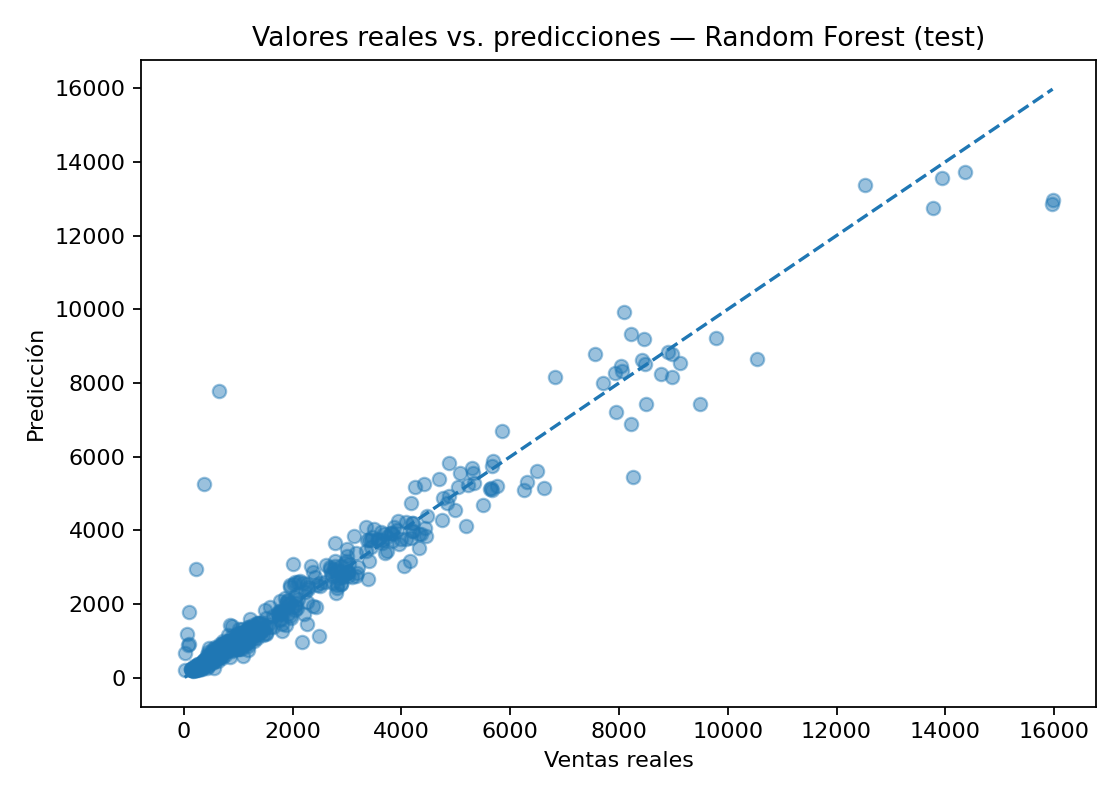

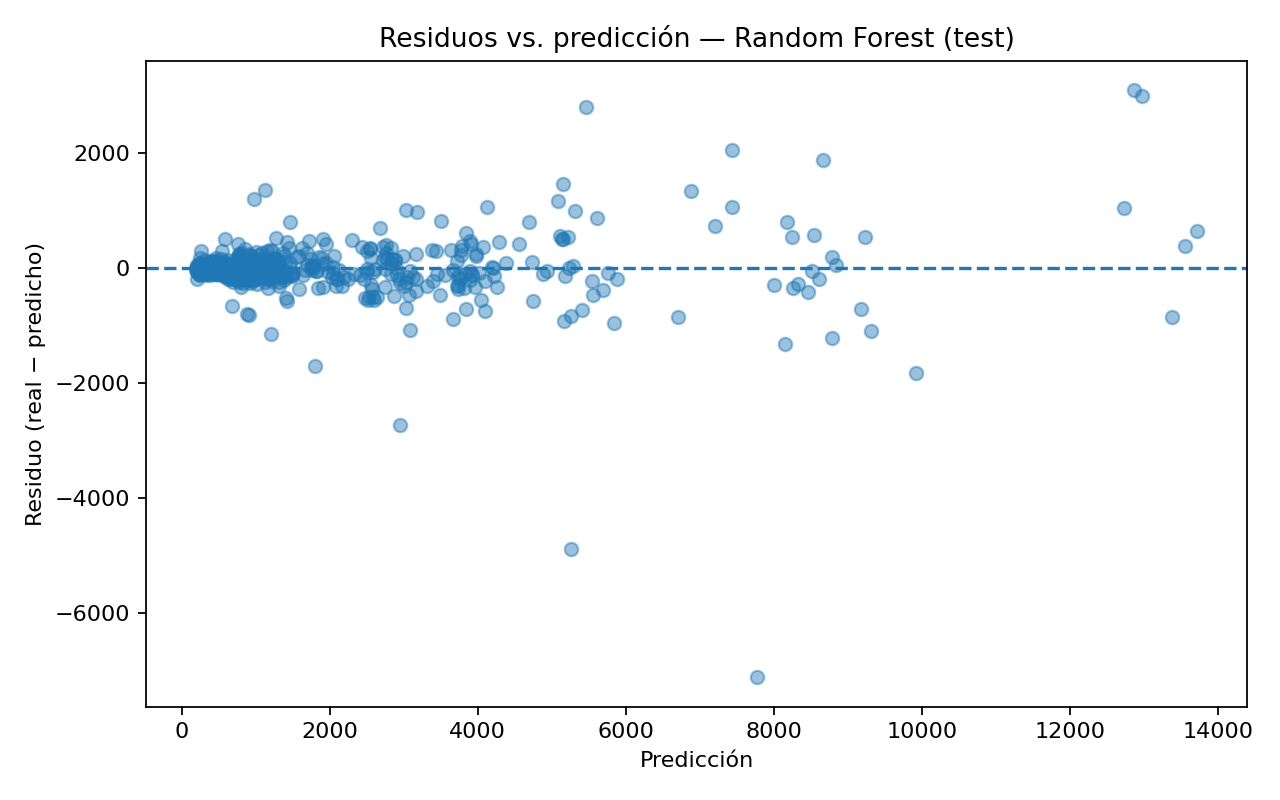

{'residuo_medio': -22.62315661233248, 'residuo_mediano': -30.847444179914376, 'desvio_residuos': 547.647970355649, 'percentil_95_error_absoluto': 864.0507504161533}


In [5]:
from IPython.display import display, Image

display(Image(filename=str(RUTA_BASE / 'output' / 'test_real_vs_predicho.png')))
display(Image(filename=str(RUTA_BASE / 'output' / 'test_residuos_vs_prediccion.png')))

residuos = resultados['predicciones']['residuo_rf']
print({
    'residuo_medio': float(residuos.mean()),
    'residuo_mediano': float(residuos.median()),
    'desvio_residuos': float(residuos.std()),
    'percentil_95_error_absoluto': float(resultados['predicciones']['error_absoluto_rf'].quantile(.95))
})

## 4. Errores por local y sección

Esta tabla permite identificar si el modelo funciona de manera homogénea en los 18 segmentos del panel. El script también exporta los 20 casos con mayor error absoluto a `output/peores_predicciones_fase3.csv`. Un sesgo medio positivo significa que, en promedio, el modelo subestima las ventas (real − predicho > 0); uno negativo indica sobreestimación.

In [6]:
display(
    resultados['errores_segmento']
    .sort_values('RMSE', ascending=False)
    .round(3)
)

peores = resultados['predicciones'].nlargest(10, 'error_absoluto_rf')[
    ['fecha_vta', 'local', 'desc_secciones', 'cantidad',
     'pred_random_forest', 'residuo_rf', 'error_absoluto_rf']
]
display(peores.round(2))

,local,desc_secciones,n,RMSE,MAE,sesgo_medio
6,Local X,Perecederos,23,1951.043,1265.604,228.593
0,Local X,Almacen,23,1374.507,889.416,-341.869
7,Local X,Produccion,23,650.091,348.965,-67.315
15,Local Y,Perecederos,43,511.174,392.250,116.963
9,Local Y,Almacen,43,421.120,342.651,-151.289
4,Local X,Insumos,23,413.669,235.910,45.960
5,Local X,Limpieza,23,369.615,247.980,14.090
1,Local X,Bazar,23,334.234,229.723,-100.019
2,Local X,Bebidas,23,300.013,204.165,40.740
11,Local Y,Bebidas,43,250.097,140.148,-0.917


,fecha_vta,local,desc_secciones,cantidad,pred_random_forest,residuo_rf,error_absoluto_rf
1139,2021-08-19,Local X,Perecederos,652.82,7774.09,-7121.27,7121.27
143,2021-08-19,Local X,Almacen,368.83,5253.50,-4884.67,4884.67
1155,2021-09-04,Local X,Perecederos,15961.14,12862.80,3098.34,3098.34
1141,2021-08-21,Local X,Perecederos,15973.15,12974.58,2998.57,2998.57
151,2021-08-27,Local X,Almacen,8263.65,5456.88,2806.77,2806.77
1305,2021-08-19,Local X,Produccion,222.71,2952.69,-2729.98,2729.98
1140,2021-08-20,Local X,Perecederos,9493.12,7436.39,2056.73,2056.73
1147,2021-08-27,Local X,Perecederos,10529.00,8657.64,1871.36,1871.36
152,2021-08-28,Local X,Almacen,8091.08,9915.88,-1824.80,1824.80
807,2021-08-19,Local X,Insumos,96.00,1797.22,-1701.22,1701.22


## 5. Interpretabilidad: importancia por permutación

La importancia por permutación mide cuánto empeora el RMSE cuando se desordena una variable manteniendo las demás. Un incremento mayor indica que el modelo depende más de esa variable para predecir en este test.

**Advertencias:** es una medida predictiva, no causal. Los rezagos y medias móviles están correlacionados; por ello, la importancia puede repartirse entre variables relacionadas. La importancia de `temperatura` no demuestra que el clima cause cambios en ventas.

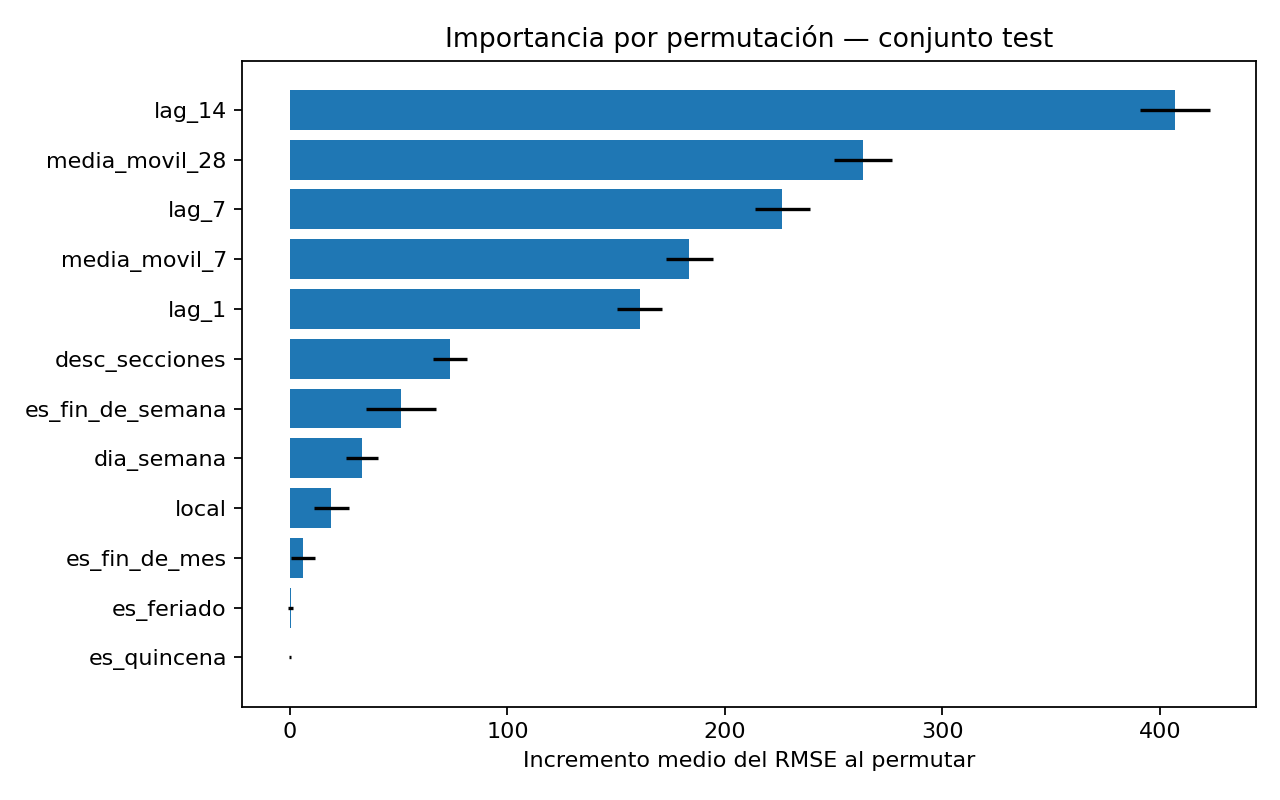

,variable,incremento_rmse_medio,desvio_std
3,lag_14,406.8751,16.1603
5,media_movil_28,263.5061,13.2210
2,lag_7,226.3559,12.6860
4,media_movil_7,183.5795,10.8735
1,lag_1,160.9044,10.3022
8,desc_secciones,73.6727,7.7133
10,es_fin_de_semana,51.0645,16.1322
9,dia_semana,33.1610,7.5164
7,local,19.0464,7.9117
13,es_fin_de_mes,5.9798,5.3832


In [7]:
display(Image(filename=str(RUTA_BASE / 'output' / 'importancia_variables_fase3.png')))
display(resultados['importancia'].round(4))

## 6. Conclusiones para completar con los resultados obtenidos

Al ejecutar este notebook, utilizar `output/resultados_fase3_test.json` para completar sin alterar los valores:

- **Rendimiento final:** indicar RMSE, MAE, MAPE y R² de Random Forest en test.
- **Comparación con la referencia:** indicar si Random Forest supera o no a lag-7 en RMSE y MAE. Esta es la comparación principal.
- **Errores:** señalar los locales/secciones con mayor RMSE y describir si existe sobreestimación o subestimación sistemática.
- **Variables:** comentar las variables con mayor importancia por permutación. No interpretar importancia como causalidad.
- **Clima:** explicar el lugar de temperatura frente a rezagos y calendario. El objetivo del proyecto es estudiar si el clima aporta capacidad predictiva adicional, no solo si el modelo predice bien.

**Limitaciones que deben permanecer explícitas:** los datos de ventas cubren enero–septiembre de 2021; solo hay dos locales y nueve secciones; la asignación local–estación meteorológica fue un supuesto documentado; la evaluación corresponde a un período de test concreto y no garantiza generalización a otros años o comercios.

In [8]:
# Inventario de archivos generados para la entrega
archivos = [
    'metricas_fase3_test.csv',
    'resultados_fase3_test.json',
    'predicciones_fase3_test.csv',
    'importancia_variables_fase3.csv',
    'errores_por_segmento_fase3.csv',
    'peores_predicciones_fase3.csv',
    'test_real_vs_predicho.png',
    'test_residuos_vs_prediccion.png',
    'importancia_variables_fase3.png',
]
for nombre in archivos:
    ruta = RUTA_BASE / 'output' / nombre
    print(('✓' if ruta.exists() else '✗'), ruta.relative_to(RUTA_BASE))

✓ output/metricas_fase3_test.csv
✓ output/resultados_fase3_test.json
✓ output/predicciones_fase3_test.csv
✓ output/importancia_variables_fase3.csv
✓ output/errores_por_segmento_fase3.csv
✓ output/peores_predicciones_fase3.csv
✓ output/test_real_vs_predicho.png
✓ output/test_residuos_vs_prediccion.png
✓ output/importancia_variables_fase3.png


## 7. Reproducibilidad y cierre

- Ejecutar este notebook después de las Partes 1 y 2.
- No volver a ejecutar el ajuste de hiperparámetros usando test.
- Conservar los CSV, JSON y gráficos generados en `output/`.
- Exportar este notebook ejecutado a HTML y completar el informe final con sus resultados reales.
- Registrar las versiones de Python, pandas y scikit-learn del entorno de ejecución. Los modelos `.joblib` deben cargarse preferentemente con la misma versión de scikit-learn con la que fueron serializados.